# Card Recognition – Test Notebook
This notebook tests the first steps of recognising a playing card:
resizing the card, cropping the corner, splitting it into rank and
suit, and cleaning up the symbol for template matching.

In [67]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

(1000, 740, 3)


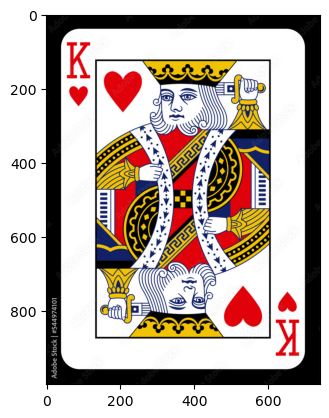

In [68]:
card = cv2.imread('test_images/single_cards/kh.jpg')
print(card.shape)

plt.imshow(cv2.cvtColor(card, cv2.COLOR_BGR2RGB))
plt.show()

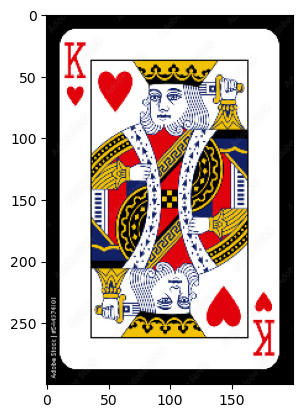

In [69]:
card = cv2.resize(card, (200, 300))   

plt.imshow(cv2.cvtColor(card, cv2.COLOR_BGR2RGB))
plt.show()

In [70]:
def clean_symbol(region, size):
    # symbol becomes white, background black
    gray = cv2.cvtColor(region, cv2.COLOR_BGR2GRAY)
    #from opencv thresholding python tutorial
    _, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    
    # AI fix: my first version kept leftover background in the
    # top-left corner, so ignore specks and shapes touching the edge.
    
    # Keep only shapes that belong to the symbol:
    # ignore tiny specks and shapes touching the edge (leftover background)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    img_h, img_w = binary.shape
    pieces = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        touches_edge = x == 0 or y == 0 or x + w == img_w or y + h == img_h
        if cv2.contourArea(c) > 10 and not touches_edge:
            pieces.append(c)

    # Nothing found: return None so the caller knows recognition failed
    if not pieces:
        return None

    # One bounding box around all pieces, so "10" stays in one piece
    x, y, w, h = cv2.boundingRect(np.vstack(pieces))
    return cv2.resize(binary[y:y+h, x:x+w], size)
    

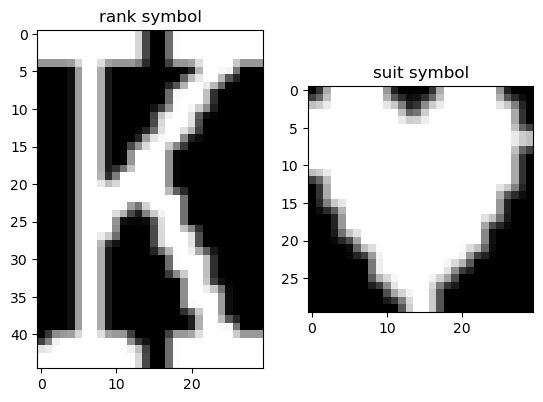

In [71]:
# Clean both symbols: ranks are tall (30 x 45), suits are square (30 x 30)
rank_symbol = clean_symbol(rank_part, (30, 45))
suit_symbol = clean_symbol(suit_part, (30, 30))

plt.subplot(1, 2, 1)
plt.imshow(rank_symbol, cmap='gray')
plt.title('rank symbol')
plt.subplot(1, 2, 2)
plt.imshow(suit_symbol, cmap='gray')
plt.title('suit symbol')
plt.show()